In [2]:
import wfdb
import numpy as np
import matplotlib.pyplot as plt

record_path = r"E:\MIMIC4\MIMIC4\physionet.org\files\mimic4wdb\0.1.0\waves\p100\p10014354\81739927\81739927_0012"

fs = 62.4725
start_sec = 18
end_sec = 26

start_sample = int(start_sec * fs)
end_sample = int(end_sec * fs)

record = wfdb.rdrecord(
    record_path,
    sampfrom=start_sample,
    sampto=end_sample
)

ecg = record.p_signal[:, record.sig_name.index("II")]
ppg = record.p_signal[:, record.sig_name.index("Pleth")]

time = np.arange(len(ecg)) / fs

print("ECG samples:", len(ecg))
print("PPG samples:", len(ppg))
print("Sampling frequency:", fs)

ECG samples: 500
PPG samples: 500
Sampling frequency: 62.4725


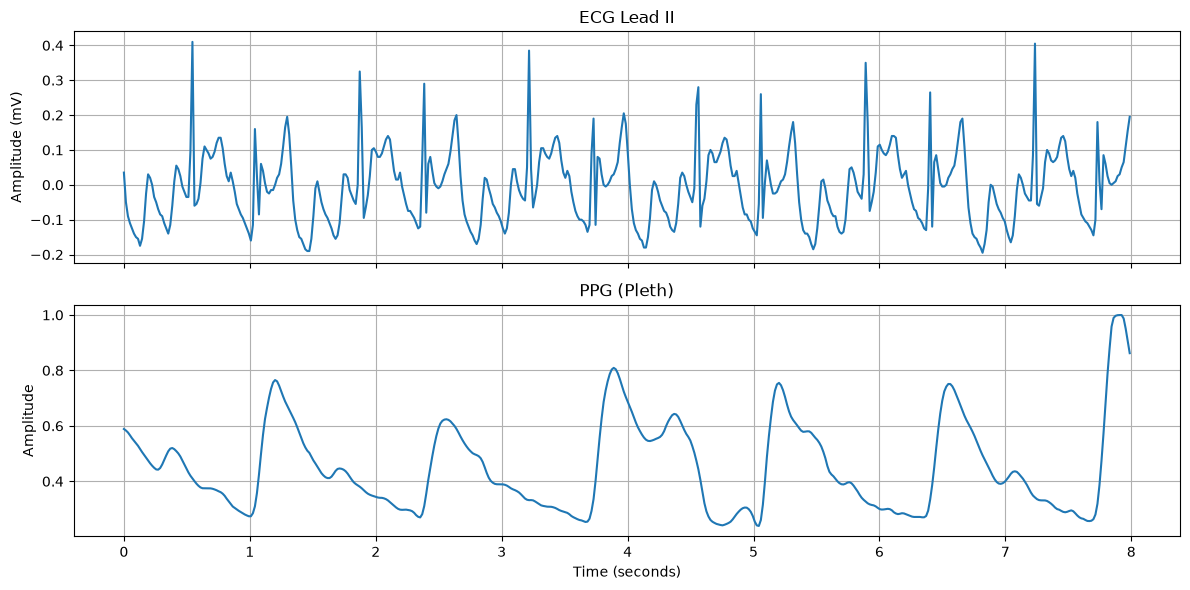

In [3]:
fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)

axes[0].plot(time, ecg)
axes[0].set_title("ECG Lead II")
axes[0].set_ylabel("Amplitude (mV)")
axes[0].grid(True)

axes[1].plot(time, ppg)
axes[1].set_title("PPG (Pleth)")
axes[1].set_xlabel("Time (seconds)")
axes[1].set_ylabel("Amplitude")
axes[1].grid(True)

plt.tight_layout()
plt.show()


In [4]:
import pywt

# Haar wavelet
cA1, cD1 = pywt.dwt(ecg, "haar")

print("Original samples:", len(ecg))
print("Approximation coefficients (cA1):", len(cA1))
print("Detail coefficients (cD1):", len(cD1))


Original samples: 500
Approximation coefficients (cA1): 250
Detail coefficients (cD1): 250


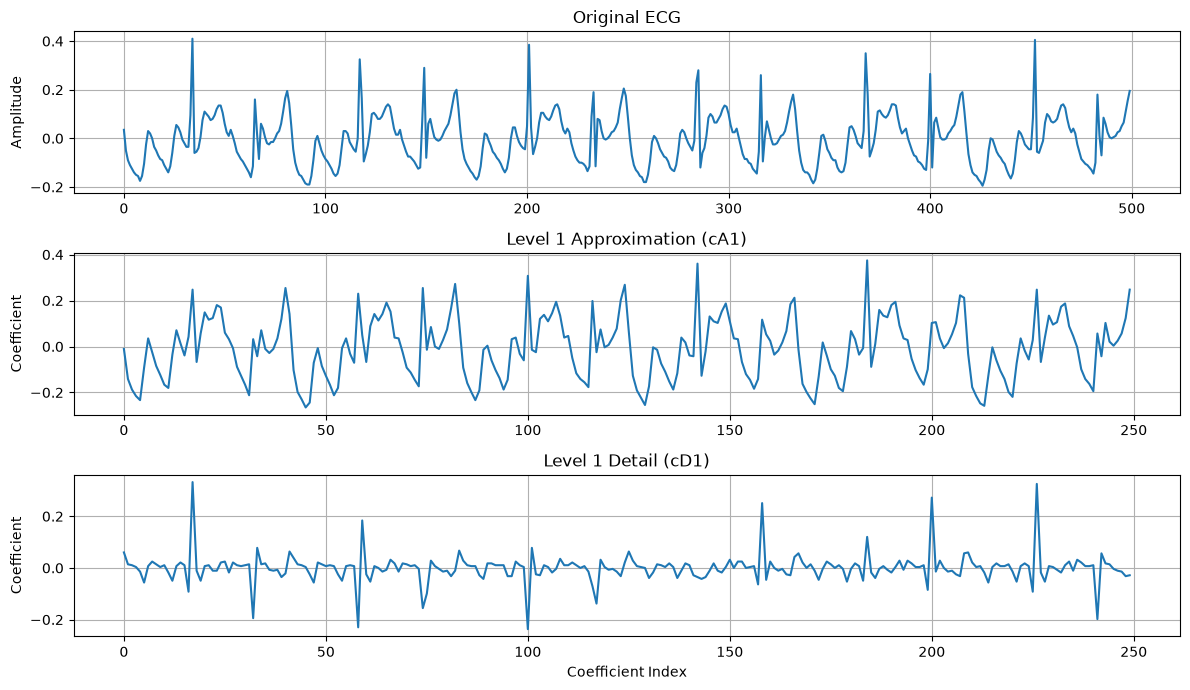

In [5]:
fig, axes = plt.subplots(3, 1, figsize=(12, 7))

axes[0].plot(ecg)
axes[0].set_title("Original ECG")
axes[0].set_ylabel("Amplitude")
axes[0].grid(True)

axes[1].plot(cA1)
axes[1].set_title("Level 1 Approximation (cA1)")
axes[1].set_ylabel("Coefficient")
axes[1].grid(True)

axes[2].plot(cD1)
axes[2].set_title("Level 1 Detail (cD1)")
axes[2].set_xlabel("Coefficient Index")
axes[2].set_ylabel("Coefficient")
axes[2].grid(True)

plt.tight_layout()
plt.show()


In [6]:
cA2, cD2 = pywt.dwt(cA1, "haar")

print("Level 1 approximation:", len(cA1))
print("Level 2 approximation:", len(cA2))
print("Level 2 detail:", len(cD2))


Level 1 approximation: 250
Level 2 approximation: 125
Level 2 detail: 125


In [7]:
cA3, cD3 = pywt.dwt(cA2, "haar")

print("cA1:", len(cA1))
print("cD1:", len(cD1))
print("cA2:", len(cA2))
print("cD2:", len(cD2))
print("cA3:", len(cA3))
print("cD3:", len(cD3))


cA1: 250
cD1: 250
cA2: 125
cD2: 125
cA3: 63
cD3: 63


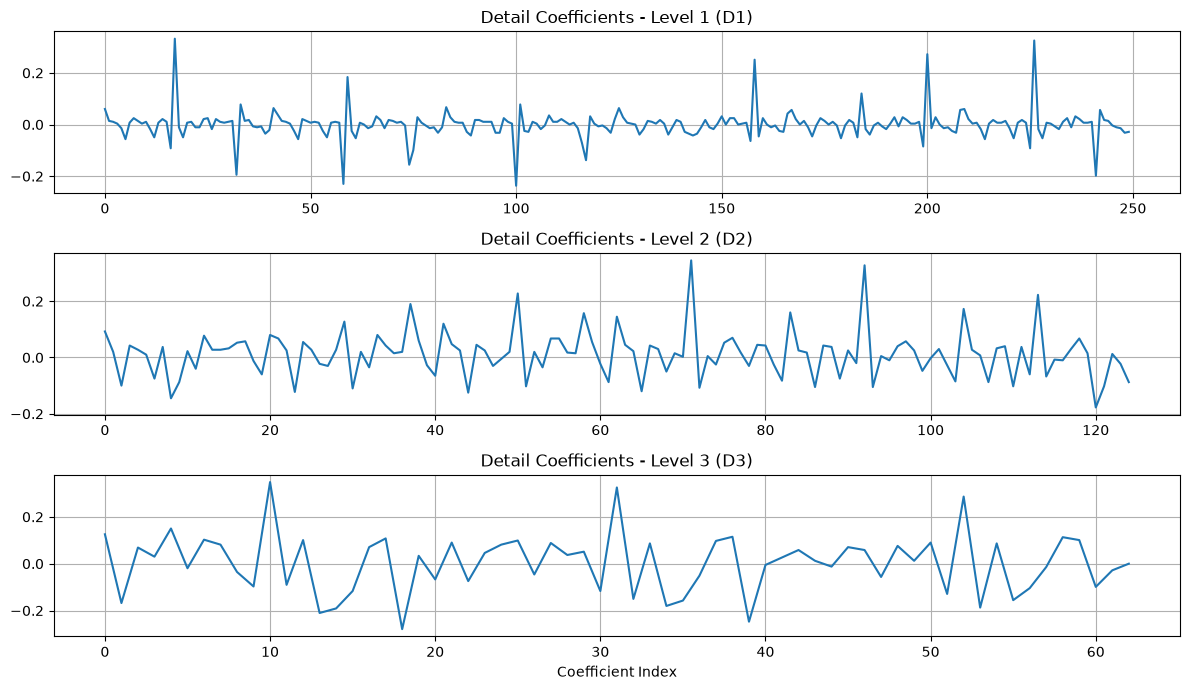

In [8]:
fig, axes = plt.subplots(3, 1, figsize=(12, 7))

axes[0].plot(cD1)
axes[0].set_title("Detail Coefficients - Level 1 (D1)")
axes[0].grid(True)

axes[1].plot(cD2)
axes[1].set_title("Detail Coefficients - Level 2 (D2)")
axes[1].grid(True)

axes[2].plot(cD3)
axes[2].set_title("Detail Coefficients - Level 3 (D3)")
axes[2].set_xlabel("Coefficient Index")
axes[2].grid(True)

plt.tight_layout()
plt.show()


In [9]:
energy_D1 = np.sum(cD1 ** 2)
energy_D2 = np.sum(cD2 ** 2)
energy_D3 = np.sum(cD3 ** 2)
energy_A3 = np.sum(cA3 ** 2)

energies = {
    "D1": energy_D1,
    "D2": energy_D2,
    "D3": energy_D3,
    "A3": energy_A3
}

for name, value in energies.items():
    print(f"{name}: {value:.4f}")

D1: 0.8166
D2: 0.8841
D3: 1.0142
A3: 2.6578


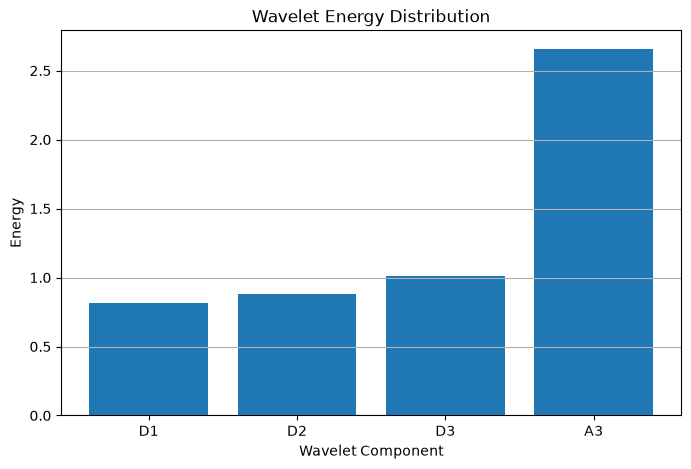

In [10]:
labels = ["D1", "D2", "D3", "A3"]
values = [energy_D1, energy_D2, energy_D3, energy_A3]

plt.figure(figsize=(8, 5))
plt.bar(labels, values)

plt.title("Wavelet Energy Distribution")
plt.xlabel("Wavelet Component")
plt.ylabel("Energy")
plt.grid(axis="y")

plt.show()

In [11]:
total_energy = sum(energies.values())

relative_energy = {
    name: (value / total_energy) * 100
    for name, value in energies.items()
}

for name, value in relative_energy.items():
    print(f"{name}: {value:.2f}%")

D1: 15.20%
D2: 16.46%
D3: 18.88%
A3: 49.47%


In [12]:
def wavelet_entropy(coefficients):
    energy = coefficients ** 2
    probability = energy / np.sum(energy)
    
    probability = probability[probability > 0]
    
    return -np.sum(probability * np.log2(probability))


entropy_D1 = wavelet_entropy(cD1)
entropy_D2 = wavelet_entropy(cD2)
entropy_D3 = wavelet_entropy(cD3)
entropy_A3 = wavelet_entropy(cA3)

entropies = {
    "D1": entropy_D1,
    "D2": entropy_D2,
    "D3": entropy_D3,
    "A3": entropy_A3
}

for name, value in entropies.items():
    print(f"{name}: {value:.4f}")

D1: 4.8191
D2: 5.2790
D3: 4.8797
A3: 5.2521


In [13]:
wavelets = {
    "Haar": "haar",
    "Daubechies": "db4",
    "Symlet": "sym4",
    "Coiflet": "coif1"
}

wavelet_results = {}

for name, wavelet in wavelets.items():
    cA, cD = pywt.dwt(ecg, wavelet)
    wavelet_results[name] = (cA, cD)
    print(f"{name}: cA = {len(cA)}, cD = {len(cD)}")

Haar: cA = 250, cD = 250
Daubechies: cA = 253, cD = 253
Symlet: cA = 253, cD = 253
Coiflet: cA = 252, cD = 252


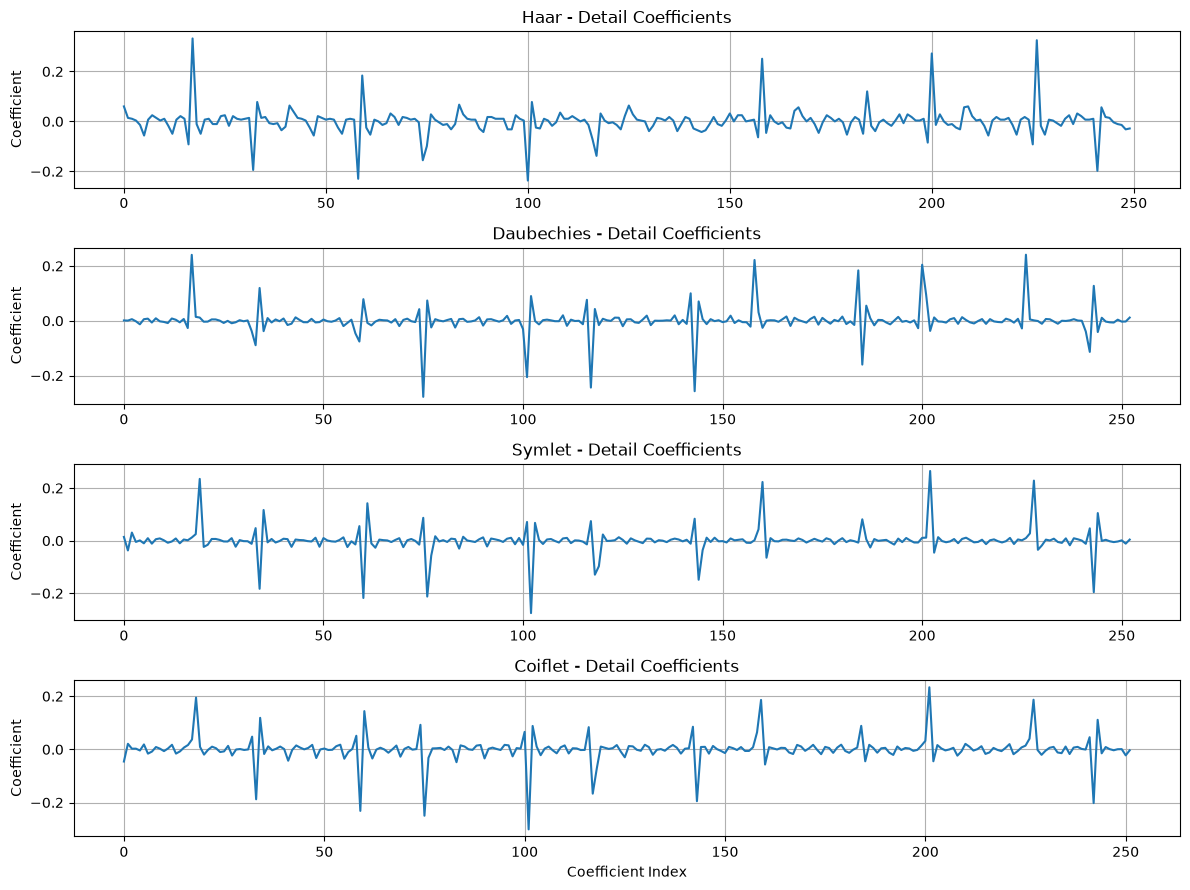

In [14]:
fig, axes = plt.subplots(4, 1, figsize=(12, 9))

for ax, (name, (cA, cD)) in zip(axes, wavelet_results.items()):
    ax.plot(cD)
    ax.set_title(f"{name} - Detail Coefficients")
    ax.set_ylabel("Coefficient")
    ax.grid(True)

axes[-1].set_xlabel("Coefficient Index")

plt.tight_layout()
plt.show()

In [15]:
wavelet_energy = {}

for name, (cA, cD) in wavelet_results.items():
    wavelet_energy[name] = np.sum(cD ** 2)

for name, energy in wavelet_energy.items():
    print(f"{name}: {energy:.4f}")

Haar: 0.8166
Daubechies: 0.6550
Symlet: 0.6401
Coiflet: 0.6648


In [16]:
reconstructed = {}

for name, (cA, cD) in wavelet_results.items():
    reconstructed[name] = pywt.idwt(cA, cD, wavelets[name])
    print(name, ":", len(reconstructed[name]))

Haar : 500
Daubechies : 500
Symlet : 500
Coiflet : 500


In [17]:
for name, rec in reconstructed.items():
    rmse = np.sqrt(np.mean((ecg - rec) ** 2))
    correlation = np.corrcoef(ecg, rec)[0, 1]

    print(f"{name}:")
    print(f"  RMSE = {rmse:.8f}")
    print(f"  Correlation = {correlation:.6f}")

Haar:
  RMSE = 0.00000000
  Correlation = 1.000000
Daubechies:
  RMSE = 0.00000000
  Correlation = 1.000000
Symlet:
  RMSE = 0.00000000
  Correlation = 1.000000
Coiflet:
  RMSE = 0.00000000
  Correlation = 1.000000


In [18]:
threshold = 0.1

print("Threshold:", threshold)

Threshold: 0.1


In [19]:
# 3-level Haar decomposition
coeffs = pywt.wavedec(ecg, "haar", level=3)

# coeffs = [cA3, cD3, cD2, cD1]

# Hard threshold only the detail coefficients
coeffs_hard = [coeffs[0]]

for detail in coeffs[1:]:
    coeffs_hard.append(
        pywt.threshold(detail, threshold, mode="hard")
    )

# Reconstruct
ecg_hard = pywt.waverec(coeffs_hard, "haar")

print("Original length:", len(ecg))
print("Denoised length:", len(ecg_hard))

Original length: 500
Denoised length: 500


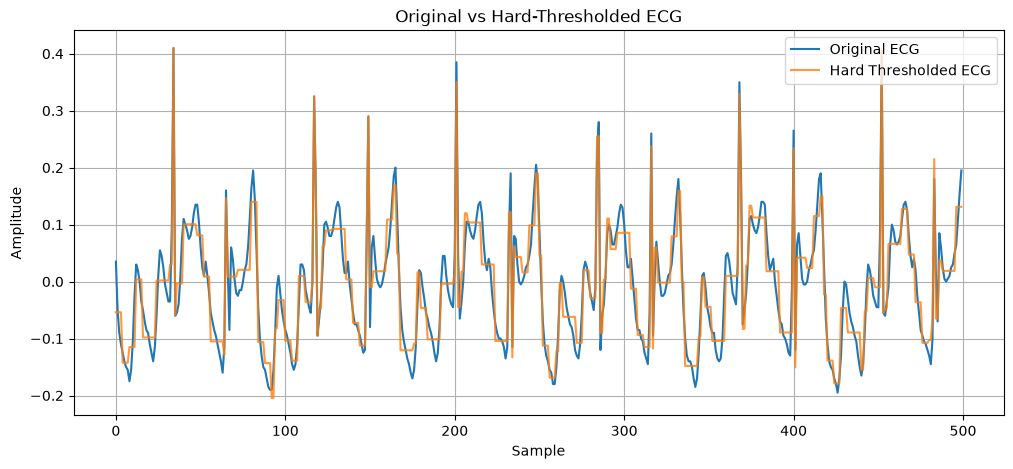

In [20]:
plt.figure(figsize=(12, 5))

plt.plot(ecg, label="Original ECG")
plt.plot(ecg_hard, label="Hard Thresholded ECG", alpha=0.8)

plt.title("Original vs Hard-Thresholded ECG")
plt.xlabel("Sample")
plt.ylabel("Amplitude")
plt.legend()
plt.grid(True)
plt.show()

In [21]:
coeffs_soft = [coeffs[0]]

for detail in coeffs[1:]:
    coeffs_soft.append(
        pywt.threshold(detail, threshold, mode="soft")
    )

ecg_soft = pywt.waverec(coeffs_soft, "haar")

print("Original length:", len(ecg))
print("Soft-denoised length:", len(ecg_soft))

Original length: 500
Soft-denoised length: 500


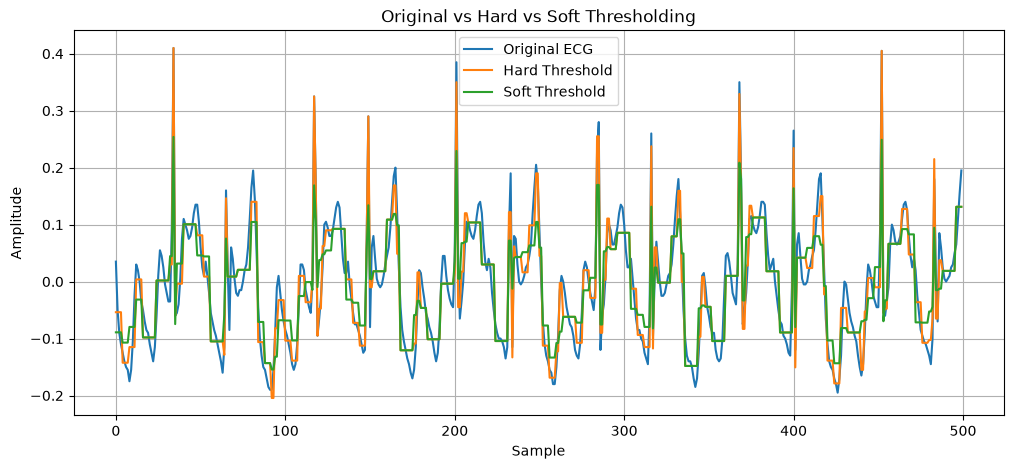

In [22]:
plt.figure(figsize=(12, 5))

plt.plot(ecg, label="Original ECG")
plt.plot(ecg_hard, label="Hard Threshold")
plt.plot(ecg_soft, label="Soft Threshold")

plt.title("Original vs Hard vs Soft Thresholding")
plt.xlabel("Sample")
plt.ylabel("Amplitude")
plt.legend()
plt.grid(True)
plt.show()

In [23]:
for name, signal in {
    "Hard Threshold": ecg_hard,
    "Soft Threshold": ecg_soft
}.items():

    rmse = np.sqrt(np.mean((ecg - signal) ** 2))
    mae = np.mean(np.abs(ecg - signal))
    correlation = np.corrcoef(ecg, signal)[0, 1]

    print(name)
    print(f"RMSE        : {rmse:.6f}")
    print(f"MAE         : {mae:.6f}")
    print(f"Correlation : {correlation:.6f}")
    print()

Hard Threshold
RMSE        : 0.033342
MAE         : 0.026335
Correlation : 0.945905

Soft Threshold
RMSE        : 0.048080
MAE         : 0.038447
Correlation : 0.890598



In [24]:
# Use finest detail coefficients to estimate noise
sigma = np.median(np.abs(coeffs[-1])) / 0.6745

# Universal threshold
universal_threshold = sigma * np.sqrt(2 * np.log(len(ecg)))

print("Estimated noise level (sigma):", sigma)
print("Universal threshold:", universal_threshold)

Estimated noise level (sigma): 0.020966843029994006
Universal threshold: 0.07391880120142134


In [25]:
coeffs_universal = [coeffs[0]]

for detail in coeffs[1:]:
    coeffs_universal.append(
        pywt.threshold(
            detail,
            universal_threshold,
            mode="hard"
        )
    )

ecg_universal = pywt.waverec(
    coeffs_universal,
    "haar"
)

print("Length:", len(ecg_universal))

Length: 500


In [26]:
rmse_universal = np.sqrt(np.mean((ecg - ecg_universal) ** 2))
mae_universal = np.mean(np.abs(ecg - ecg_universal))
corr_universal = np.corrcoef(ecg, ecg_universal)[0, 1]

print("Universal Threshold:")
print(f"RMSE        : {rmse_universal:.6f}")
print(f"MAE         : {mae_universal:.6f}")
print(f"Correlation : {corr_universal:.6f}")

Universal Threshold:
RMSE        : 0.024753
MAE         : 0.019983
Correlation : 0.970559


In [27]:
# Estimate noise from finest detail coefficients
sigma = np.median(np.abs(coeffs[-1])) / 0.6745
noise_var = sigma ** 2

bayes_thresholds = []

for detail in coeffs[1:]:
    signal_var = max(np.var(detail) - noise_var, 0)

    if signal_var == 0:
        threshold_bayes = np.max(np.abs(detail))
    else:
        threshold_bayes = noise_var / np.sqrt(signal_var)

    bayes_thresholds.append(threshold_bayes)

print("Noise sigma:", sigma)
print("BayesShrink thresholds:")

for i, value in enumerate(bayes_thresholds, start=1):
    print(f"D{i}: {value:.6f}")

Noise sigma: 0.020966843029994006
BayesShrink thresholds:
D1: 0.003515
D2: 0.005468
D3: 0.008269


In [28]:
coeffs_bayes = [coeffs[0]]

for detail, thr in zip(coeffs[1:], bayes_thresholds):
    coeffs_bayes.append(
        pywt.threshold(detail, thr, mode="soft")
    )

ecg_bayes = pywt.waverec(coeffs_bayes, "haar")

print("Original length:", len(ecg))
print("BayesShrink length:", len(ecg_bayes))

Original length: 500
BayesShrink length: 500


In [29]:
rmse_bayes = np.sqrt(np.mean((ecg - ecg_bayes) ** 2))
mae_bayes = np.mean(np.abs(ecg - ecg_bayes))

nrmse_bayes = rmse_bayes / (np.max(ecg) - np.min(ecg))

prd_bayes = (
    np.sqrt(np.sum((ecg - ecg_bayes) ** 2) / np.sum(ecg ** 2))
    * 100
)

corr_bayes = np.corrcoef(ecg, ecg_bayes)[0, 1]

print("BayesShrink:")
print(f"RMSE        : {rmse_bayes:.6f}")
print(f"MAE         : {mae_bayes:.6f}")
print(f"NRMSE       : {nrmse_bayes:.6f}")
print(f"PRD         : {prd_bayes:.4f}%")
print(f"Correlation : {corr_bayes:.6f}")

BayesShrink:
RMSE        : 0.006133
MAE         : 0.005369
NRMSE       : 0.010137
PRD         : 5.9546%
Correlation : 0.998432


In [30]:
# CWT of ECG using Morlet wavelet
# Frequency range for final CWT analysis
freq_min = 1
freq_max = 30

# Morlet scales
scales_morl = np.arange(1, 64)
freq_morl = pywt.scale2frequency("morl", scales_morl) * fs

# Mexican Hat scales
scales_mexh = np.arange(1, 64)
freq_mexh = pywt.scale2frequency("mexh", scales_mexh) * fs

print("Morlet frequency range:",
      freq_morl.min(), "to", freq_morl.max(), "Hz")

print("Mexican Hat frequency range:",
      freq_mexh.min(), "to", freq_mexh.max(), "Hz")

Morlet frequency range: 0.8056969246031745 to 50.758906249999995 Hz
Mexican Hat frequency range: 0.247906746031746 to 15.618125 Hz


In [31]:
# Common frequency range for fair CWT comparison

target_freqs = np.geomspace(1, 30, 64)

# Convert frequencies to scales for each wavelet
scales_morl = pywt.frequency2scale("morl", target_freqs / fs)
scales_mexh = pywt.frequency2scale("mexh", target_freqs / fs)

# CWT
cwt_morl, freq_morl = pywt.cwt(
    ecg, scales_morl, "morl", sampling_period=1/fs
)

cwt_mexh, freq_mexh = pywt.cwt(
    ecg, scales_mexh, "mexh", sampling_period=1/fs
)

print("Morlet:", freq_morl.min(), "to", freq_morl.max(), "Hz")
print("Mexican Hat:", freq_mexh.min(), "to", freq_mexh.max(), "Hz")

Morlet: 1.0 to 30.0 Hz
Mexican Hat: 1.0 to 30.0 Hz


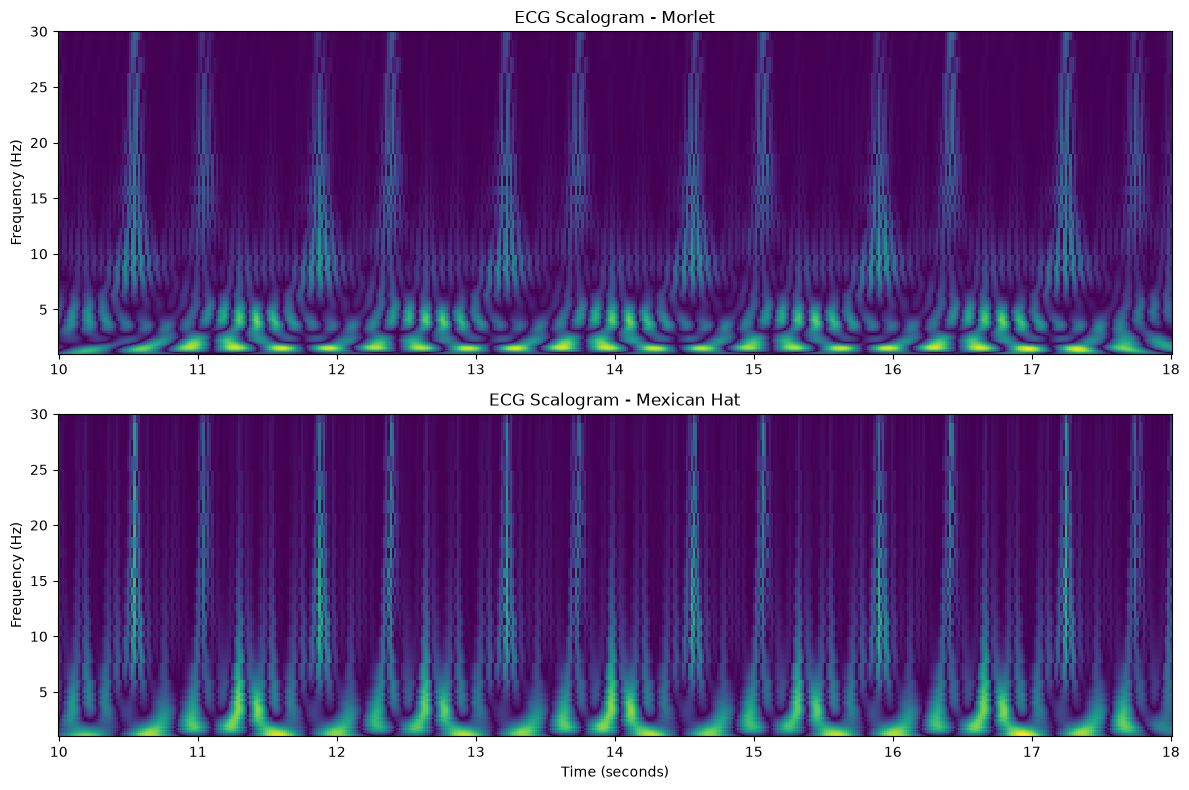

In [32]:
fig, axes = plt.subplots(2, 1, figsize=(12, 8))

# Morlet
axes[0].pcolormesh(
    np.linspace(10, 18, len(ecg)),
    freq_morl,
    np.abs(cwt_morl),
    shading="auto"
)
axes[0].set_title("ECG Scalogram - Morlet")
axes[0].set_ylabel("Frequency (Hz)")
axes[0].set_ylim(1, 30)

# Mexican Hat
axes[1].pcolormesh(
    np.linspace(10, 18, len(ecg)),
    freq_mexh,
    np.abs(cwt_mexh),
    shading="auto"
)
axes[1].set_title("ECG Scalogram - Mexican Hat")
axes[1].set_xlabel("Time (seconds)")
axes[1].set_ylabel("Frequency (Hz)")
axes[1].set_ylim(1, 30)

plt.tight_layout()
plt.show()

In [33]:
from scipy.signal import butter, filtfilt

# Butterworth bandpass filter
lowcut = 0.5
highcut = 30

b, a = butter(
    N=4,
    Wn=[lowcut, highcut],
    btype="bandpass",
    fs=fs
)

ecg_butter = filtfilt(b, a, ecg)

print("Original length:", len(ecg))
print("Filtered length:", len(ecg_butter))

Original length: 500
Filtered length: 500


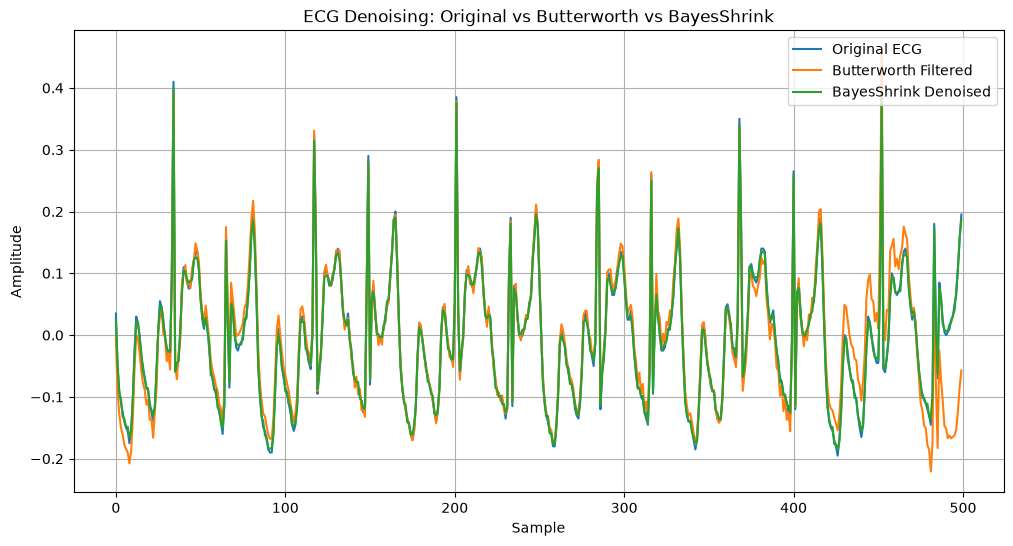

In [34]:
plt.figure(figsize=(12, 6))

plt.plot(ecg, label="Original ECG")
plt.plot(ecg_butter, label="Butterworth Filtered")
plt.plot(ecg_bayes, label="BayesShrink Denoised")

plt.xlabel("Sample")
plt.ylabel("Amplitude")
plt.title("ECG Denoising: Original vs Butterworth vs BayesShrink")
plt.legend()
plt.grid(True)

plt.show()

In [35]:
# Butterworth metrics
rmse_butter = np.sqrt(np.mean((ecg - ecg_butter) ** 2))
mae_butter = np.mean(np.abs(ecg - ecg_butter))
corr_butter = np.corrcoef(ecg, ecg_butter)[0, 1]

# BayesShrink metrics
rmse_bayes = np.sqrt(np.mean((ecg - ecg_bayes) ** 2))
mae_bayes = np.mean(np.abs(ecg - ecg_bayes))
corr_bayes = np.corrcoef(ecg, ecg_bayes)[0, 1]

print("Butterworth:")
print(f"RMSE        : {rmse_butter:.6f}")
print(f"MAE         : {mae_butter:.6f}")
print(f"Correlation : {corr_butter:.6f}")

print("\nBayesShrink:")
print(f"RMSE        : {rmse_bayes:.6f}")
print(f"MAE         : {mae_bayes:.6f}")
print(f"Correlation : {corr_bayes:.6f}")

Butterworth:
RMSE        : 0.039629
MAE         : 0.021790
Correlation : 0.928549

BayesShrink:
RMSE        : 0.006133
MAE         : 0.005369
Correlation : 0.998432


In [36]:
from scipy.signal import find_peaks

min_distance = int(0.4 * fs)

peaks_original, _ = find_peaks(
    ecg,
    distance=min_distance,
    prominence=0.08
)

peaks_bayes, _ = find_peaks(
    ecg_bayes,
    distance=min_distance,
    prominence=0.08
)

print("Original peaks:", len(peaks_original))
print("BayesShrink peaks:", len(peaks_bayes))

Original peaks: 12
BayesShrink peaks: 12


In [37]:
print("Original peak positions:")
print(peaks_original)

print("\nBayesShrink peak positions:")
print(peaks_bayes)

print("\nPeak position differences:")
print(peaks_bayes - peaks_original)

Original peak positions:
[ 34  81 117 149 201 248 285 316 368 400 452 483]

BayesShrink peak positions:
[ 34  81 117 149 201 248 285 316 368 400 452 483]

Peak position differences:
[0 0 0 0 0 0 0 0 0 0 0 0]


In [38]:
morph_corr = np.corrcoef(ecg, ecg_bayes)[0, 1]

print(f"Morphological correlation: {morph_corr:.6f}")

Morphological correlation: 0.998432


In [39]:
# Add controlled Gaussian noise at 10 dB SNR

np.random.seed(42)

target_snr_db = 10

signal_power = np.mean(ecg ** 2)
noise_power = signal_power / (10 ** (target_snr_db / 10))

noise = np.random.normal(
    0,
    np.sqrt(noise_power),
    len(ecg)
)

ecg_noisy = ecg + noise

print("Signal power:", signal_power)
print("Noise power:", noise_power)
print("Noisy ECG length:", len(ecg_noisy))

Signal power: 0.0106075
Noise power: 0.00106075
Noisy ECG length: 500


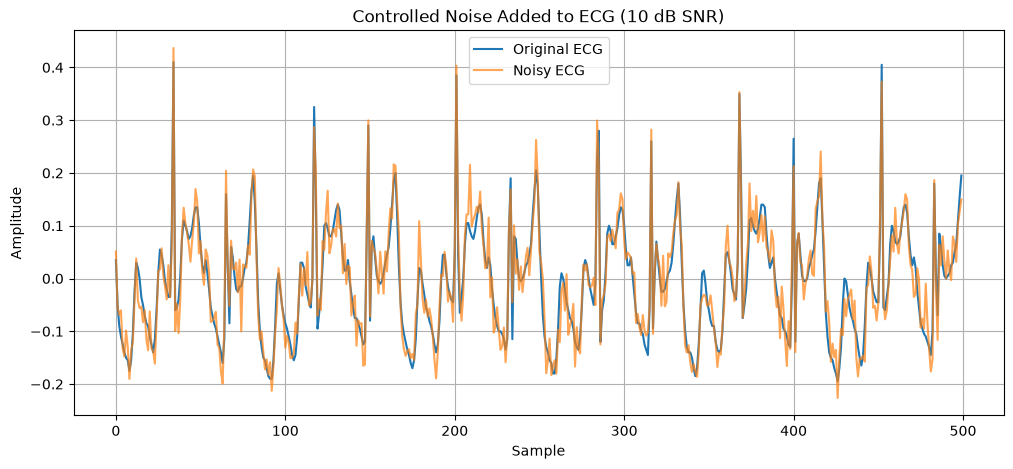

In [40]:
plt.figure(figsize=(12, 5))

plt.plot(ecg, label="Original ECG")
plt.plot(ecg_noisy, label="Noisy ECG", alpha=0.7)

plt.xlabel("Sample")
plt.ylabel("Amplitude")
plt.title("Controlled Noise Added to ECG (10 dB SNR)")
plt.legend()
plt.grid(True)

plt.show()

In [41]:
# Calculate SNR before denoising

noise_actual = ecg_noisy - ecg

snr_before = 10 * np.log10(
    np.sum(ecg ** 2) / np.sum(noise_actual ** 2)
)

print(f"Target SNR : {target_snr_db:.2f} dB")
print(f"Actual SNR : {snr_before:.2f} dB")

Target SNR : 10.00 dB
Actual SNR : 10.17 dB


In [42]:
# DWT of noisy ECG
coeffs_noisy = pywt.wavedec(ecg_noisy, "haar", level=3)

# Estimate noise from finest detail coefficients
sigma_noisy = np.median(
    np.abs(coeffs_noisy[-1])
) / 0.6745

noise_var_noisy = sigma_noisy ** 2

print("Estimated noise sigma:", sigma_noisy)

# BayesShrink thresholds
bayes_thresholds_noisy = []

for detail in coeffs_noisy[1:]:
    signal_var = max(np.var(detail) - noise_var_noisy, 0)

    if signal_var == 0:
        threshold_bayes = np.max(np.abs(detail))
    else:
        threshold_bayes = noise_var_noisy / np.sqrt(signal_var)

    bayes_thresholds_noisy.append(threshold_bayes)

print("BayesShrink thresholds:")

for i, value in enumerate(bayes_thresholds_noisy, start=1):
    print(f"D{i}: {value:.6f}")

Estimated noise sigma: 0.04163624754103783
BayesShrink thresholds:
D1: 0.014903
D2: 0.023831
D3: 0.034503


In [43]:
# Apply BayesShrink to noisy ECG

coeffs_bayes_noisy = [coeffs_noisy[0]]

for detail, threshold_bayes in zip(
    coeffs_noisy[1:],
    bayes_thresholds_noisy
):
    coeffs_bayes_noisy.append(
        pywt.threshold(
            detail,
            threshold_bayes,
            mode="soft"
        )
    )

ecg_denoised = pywt.waverec(
    coeffs_bayes_noisy,
    "haar"
)

print("Noisy ECG length:", len(ecg_noisy))
print("Denoised ECG length:", len(ecg_denoised))

Noisy ECG length: 500
Denoised ECG length: 500


In [44]:
# Compare noisy and denoised ECG with original reference

def calculate_metrics(reference, signal):
    error = reference - signal

    rmse = np.sqrt(np.mean(error ** 2))
    mae = np.mean(np.abs(error))
    nrmse = rmse / (np.max(reference) - np.min(reference))
    prd = 100 * np.sqrt(np.sum(error ** 2) / np.sum(reference ** 2))
    correlation = np.corrcoef(reference, signal)[0, 1]

    return rmse, mae, nrmse, prd, correlation


# SNR after denoising
noise_after = ecg_denoised - ecg

snr_after = 10 * np.log10(
    np.sum(ecg ** 2) / np.sum(noise_after ** 2)
)

snr_improvement = snr_after - snr_before

# Error metrics
rmse_noisy, mae_noisy, nrmse_noisy, prd_noisy, corr_noisy = \
    calculate_metrics(ecg, ecg_noisy)

rmse_denoised, mae_denoised, nrmse_denoised, prd_denoised, corr_denoised = \
    calculate_metrics(ecg, ecg_denoised)


print(f"SNR before denoising : {snr_before:.2f} dB")
print(f"SNR after denoising  : {snr_after:.2f} dB")
print(f"SNR improvement      : {snr_improvement:.2f} dB")

print("\nNoisy ECG:")
print(f"RMSE        : {rmse_noisy:.6f}")
print(f"MAE         : {mae_noisy:.6f}")
print(f"NRMSE       : {nrmse_noisy:.6f}")
print(f"PRD         : {prd_noisy:.2f}%")
print(f"Correlation : {corr_noisy:.6f}")

print("\nDenoised ECG:")
print(f"RMSE        : {rmse_denoised:.6f}")
print(f"MAE         : {mae_denoised:.6f}")
print(f"NRMSE       : {nrmse_denoised:.6f}")
print(f"PRD         : {prd_denoised:.2f}%")
print(f"Correlation : {corr_denoised:.6f}")

SNR before denoising : 10.17 dB
SNR after denoising  : 10.88 dB
SNR improvement      : 0.71 dB

Noisy ECG:
RMSE        : 0.031927
MAE         : 0.025379
NRMSE       : 0.052773
PRD         : 31.00%
Correlation : 0.954355

Denoised ECG:
RMSE        : 0.029428
MAE         : 0.023137
NRMSE       : 0.048641
PRD         : 28.57%
Correlation : 0.958178


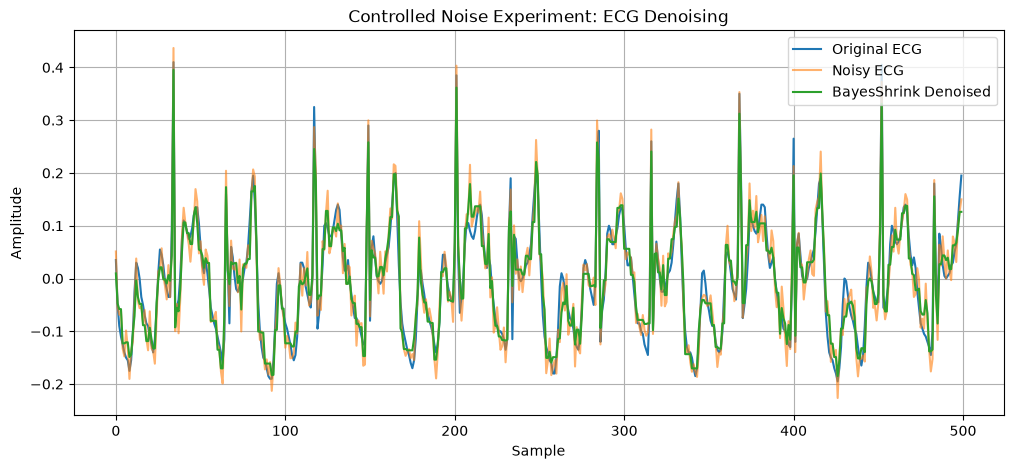

In [45]:
plt.figure(figsize=(12, 5))

plt.plot(ecg, label="Original ECG")
plt.plot(ecg_noisy, label="Noisy ECG", alpha=0.6)
plt.plot(ecg_denoised, label="BayesShrink Denoised")

plt.xlabel("Sample")
plt.ylabel("Amplitude")
plt.title("Controlled Noise Experiment: ECG Denoising")
plt.legend()
plt.grid(True)
plt.show()


In [46]:
# Compare wavelet detail energy

coeffs_original = pywt.wavedec(ecg, "haar", level=3)
coeffs_noisy = pywt.wavedec(ecg_noisy, "haar", level=3)
coeffs_denoised = pywt.wavedec(ecg_denoised, "haar", level=3)

for i, level in enumerate(["D3", "D2", "D1"], start=1):
    original_energy = np.sum(coeffs_original[i] ** 2)
    noisy_energy = np.sum(coeffs_noisy[i] ** 2)
    denoised_energy = np.sum(coeffs_denoised[i] ** 2)

    print(f"{level}:")
    print(f"  Original : {original_energy:.4f}")
    print(f"  Noisy    : {noisy_energy:.4f}")
    print(f"  Denoised : {denoised_energy:.4f}")

D3:
  Original : 1.0142
  Noisy    : 0.9725
  Denoised : 0.8053
D2:
  Original : 0.8841
  Noisy    : 0.9008
  Denoised : 0.5900
D1:
  Original : 0.8166
  Noisy    : 1.0646
  Denoised : 0.5802


In [47]:
from scipy.stats import entropy

# Histogram-based probability distribution
hist, _ = np.histogram(ecg, bins=50, density=True)

# Normalize to probabilities
probabilities = hist / np.sum(hist)

# Remove zero probabilities
probabilities = probabilities[probabilities > 0]

shannon_entropy = entropy(probabilities, base=2)

print(f"Shannon Entropy: {shannon_entropy:.4f} bits")

Shannon Entropy: 4.9199 bits


In [48]:
from scipy.signal import welch

# Estimate power spectral density
frequencies, psd = welch(
    ecg,
    fs=fs,
    nperseg=256
)

# Convert PSD into probability distribution
psd_probability = psd / np.sum(psd)

# Remove zero values
psd_probability = psd_probability[psd_probability > 0]

# Spectral entropy
spectral_entropy = entropy(
    psd_probability,
    base=2
)

print(f"Spectral Entropy: {spectral_entropy:.4f} bits")

Spectral Entropy: 5.1940 bits


In [49]:
import time

# BayesShrink timing
start = time.perf_counter()

for _ in range(100):
    coeffs = pywt.wavedec(ecg_noisy, "haar", level=3)

    coeffs_denoised = [coeffs[0]]

    for detail, threshold_bayes in zip(
        coeffs[1:], bayes_thresholds_noisy
    ):
        coeffs_denoised.append(
            pywt.threshold(detail, threshold_bayes, mode="soft")
        )

    pywt.waverec(coeffs_denoised, "haar")

bayes_time = (time.perf_counter() - start) / 100


# Butterworth timing
start = time.perf_counter()

for _ in range(100):
    filtfilt(b, a, ecg_noisy)

butter_time = (time.perf_counter() - start) / 100


print(f"BayesShrink time    : {bayes_time*1000:.4f} ms")
print(f"Butterworth time    : {butter_time*1000:.4f} ms")

BayesShrink time    : 0.0869 ms
Butterworth time    : 0.1010 ms


In [50]:
# PPG: 3-level DWT

ppg_coeffs = pywt.wavedec(ppg, "haar", level=3)

cA3_ppg, cD3_ppg, cD2_ppg, cD1_ppg = ppg_coeffs

print("Original samples:", len(ppg))
print("A3:", len(cA3_ppg))
print("D3:", len(cD3_ppg))
print("D2:", len(cD2_ppg))
print("D1:", len(cD1_ppg))


Original samples: 500
A3: 63
D3: 63
D2: 125
D1: 250


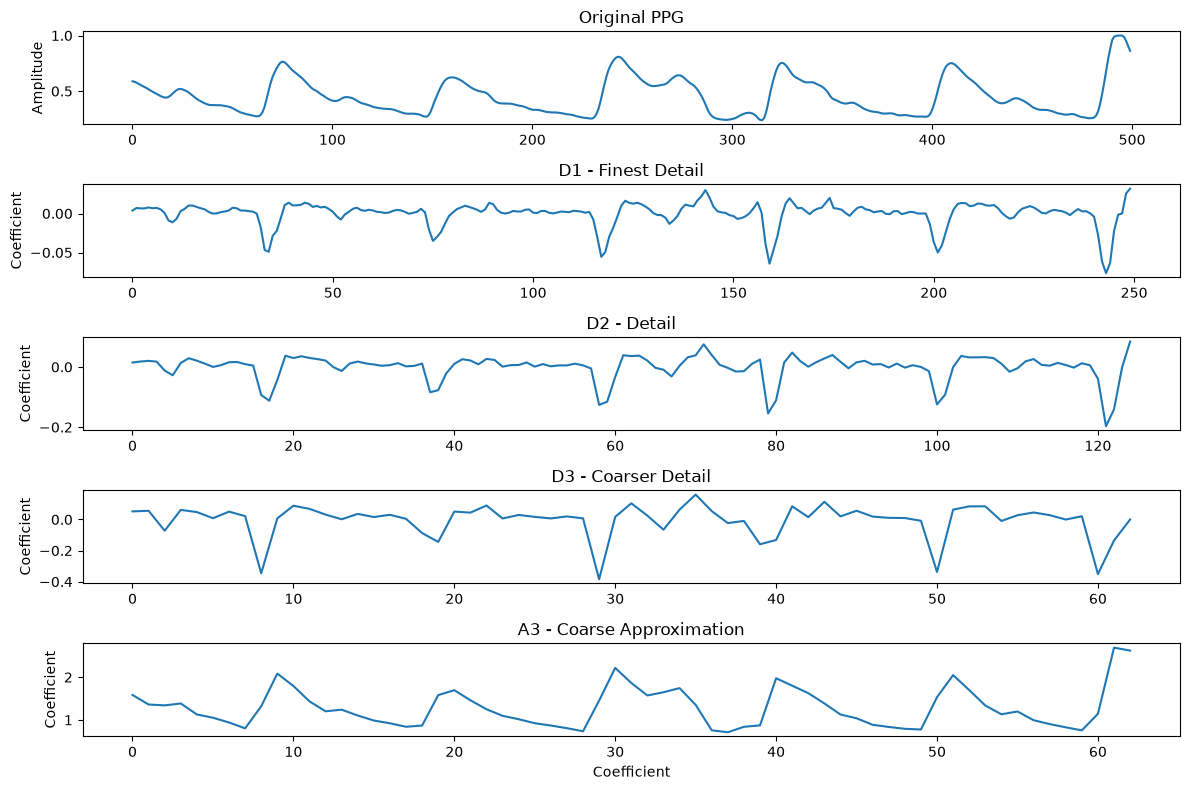

In [51]:
plt.figure(figsize=(12, 8))

plt.subplot(5, 1, 1)
plt.plot(ppg)
plt.title("Original PPG")
plt.ylabel("Amplitude")

plt.subplot(5, 1, 2)
plt.plot(cD1_ppg)
plt.title("D1 - Finest Detail")
plt.ylabel("Coefficient")

plt.subplot(5, 1, 3)
plt.plot(cD2_ppg)
plt.title("D2 - Detail")
plt.ylabel("Coefficient")

plt.subplot(5, 1, 4)
plt.plot(cD3_ppg)
plt.title("D3 - Coarser Detail")
plt.ylabel("Coefficient")

plt.subplot(5, 1, 5)
plt.plot(cA3_ppg)
plt.title("A3 - Coarse Approximation")
plt.xlabel("Coefficient")
plt.ylabel("Coefficient")

plt.tight_layout()
plt.show()

In [52]:
# PPG wavelet energy

ppg_energies = {
    "D1": np.sum(cD1_ppg ** 2),
    "D2": np.sum(cD2_ppg ** 2),
    "D3": np.sum(cD3_ppg ** 2),
    "A3": np.sum(cA3_ppg ** 2)
}

for name, value in ppg_energies.items():
    print(f"{name}: {value:.4f}")

D1: 0.0606
D2: 0.2394
D3: 0.7405
A3: 117.1673


In [53]:
# PPG wavelet entropy

ppg_entropies = {
    "D1": wavelet_entropy(cD1_ppg),
    "D2": wavelet_entropy(cD2_ppg),
    "D3": wavelet_entropy(cD3_ppg),
    "A3": wavelet_entropy(cA3_ppg)
}

for name, value in ppg_entropies.items():
    print(f"{name}: {value:.4f}")

D1: 5.5930
D2: 4.6814
D3: 3.7294
A3: 5.6351


In [54]:
# Relative wavelet energy: ECG vs PPG

ecg_total = sum(energies.values())
ppg_total = sum(ppg_energies.values())

print("ECG relative energy:")
for name, value in energies.items():
    print(f"{name}: {100 * value / ecg_total:.2f}%")

print("\nPPG relative energy:")
for name, value in ppg_energies.items():
    print(f"{name}: {100 * value / ppg_total:.2f}%")

ECG relative energy:
D1: 15.20%
D2: 16.46%
D3: 18.88%
A3: 49.47%

PPG relative energy:
D1: 0.05%
D2: 0.20%
D3: 0.63%
A3: 99.12%


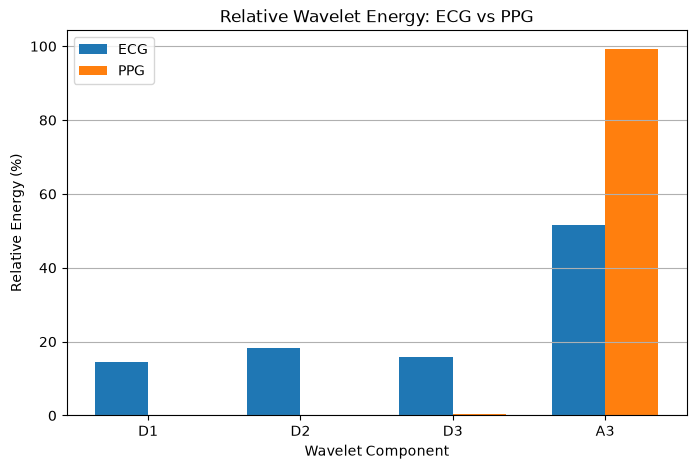

In [55]:
components = ["D1", "D2", "D3", "A3"]

ecg_relative = [14.39, 18.19, 15.90, 51.52]
ppg_relative = [0.04, 0.14, 0.52, 99.30]

x = np.arange(len(components))
width = 0.35

plt.figure(figsize=(8, 5))

plt.bar(x - width/2, ecg_relative, width, label="ECG")
plt.bar(x + width/2, ppg_relative, width, label="PPG")

plt.xticks(x, components)
plt.xlabel("Wavelet Component")
plt.ylabel("Relative Energy (%)")
plt.title("Relative Wavelet Energy: ECG vs PPG")
plt.legend()
plt.grid(axis="y")

plt.show()

In [56]:
# PPG CWT using Morlet wavelet

target_freqs = np.geomspace(1, 30, 64)

scales_ppg = pywt.frequency2scale(
    "morl",
    target_freqs / fs
)

cwt_ppg, freq_ppg = pywt.cwt(
    ppg,
    scales_ppg,
    "morl",
    sampling_period=1/fs
)

print("CWT shape:", cwt_ppg.shape)
print("Frequency range:", freq_ppg.min(), "to", freq_ppg.max(), "Hz")

CWT shape: (64, 500)
Frequency range: 1.0 to 30.0 Hz


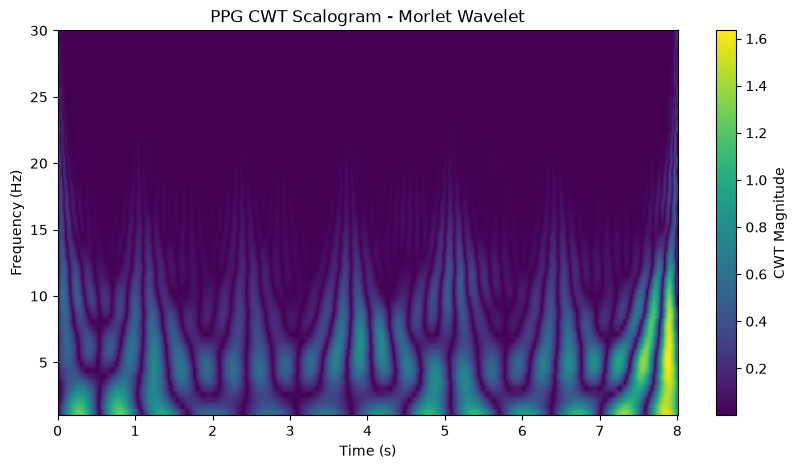

In [57]:
plt.figure(figsize=(10, 5))

plt.imshow(
    np.abs(cwt_ppg),
    extent=[0, len(ppg) / fs, freq_ppg.min(), freq_ppg.max()],
    aspect="auto",
    origin="lower"
)

plt.colorbar(label="CWT Magnitude")
plt.xlabel("Time (s)")
plt.ylabel("Frequency (Hz)")
plt.title("PPG CWT Scalogram - Morlet Wavelet")

plt.show()


In [58]:
# PPG CWT: Morlet vs Mexican Hat

scales_morl_ppg = pywt.frequency2scale(
    "morl",
    target_freqs / fs
)

scales_mexh_ppg = pywt.frequency2scale(
    "mexh",
    target_freqs / fs
)

cwt_morl_ppg, freq_morl_ppg = pywt.cwt(
    ppg,
    scales_morl_ppg,
    "morl",
    sampling_period=1/fs
)

cwt_mexh_ppg, freq_mexh_ppg = pywt.cwt(
    ppg,
    scales_mexh_ppg,
    "mexh",
    sampling_period=1/fs
)

print("Morlet:", freq_morl_ppg.min(), "to", freq_morl_ppg.max(), "Hz")
print("Mexican Hat:", freq_mexh_ppg.min(), "to", freq_mexh_ppg.max(), "Hz")

Morlet: 1.0 to 30.0 Hz
Mexican Hat: 1.0 to 30.0 Hz


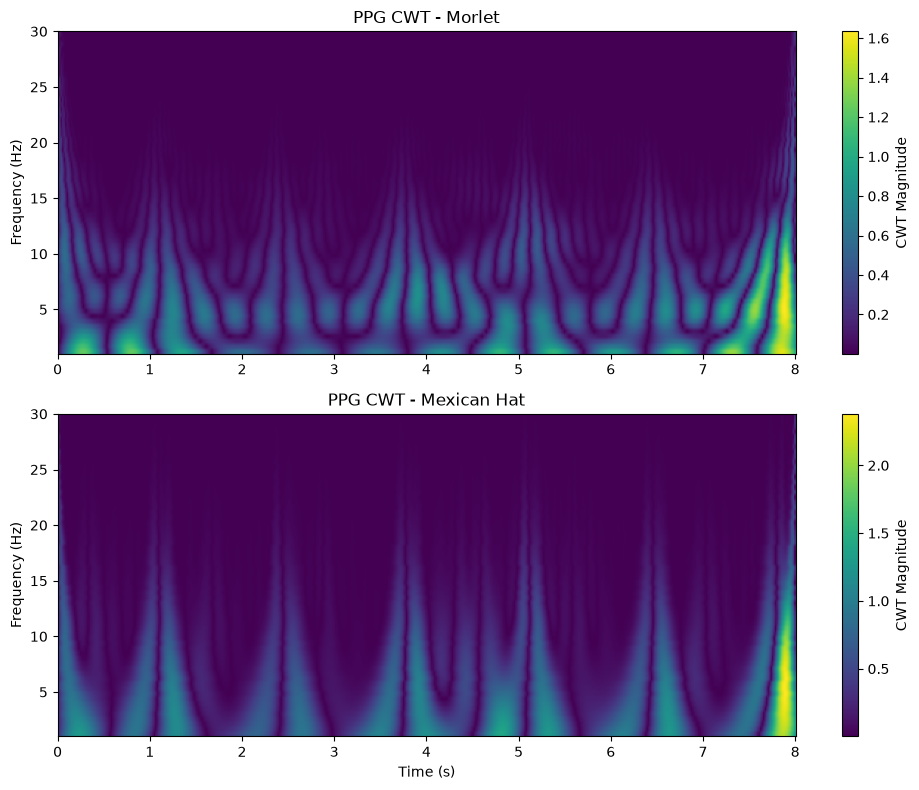

In [59]:
fig, axes = plt.subplots(2, 1, figsize=(10, 8))

# Morlet
im1 = axes[0].imshow(
    np.abs(cwt_morl_ppg),
    extent=[0, len(ppg) / fs, 1, 30],
    aspect="auto",
    origin="lower"
)
axes[0].set_title("PPG CWT - Morlet")
axes[0].set_ylabel("Frequency (Hz)")
fig.colorbar(im1, ax=axes[0], label="CWT Magnitude")

# Mexican Hat
im2 = axes[1].imshow(
    np.abs(cwt_mexh_ppg),
    extent=[0, len(ppg) / fs, 1, 30],
    aspect="auto",
    origin="lower"
)
axes[1].set_title("PPG CWT - Mexican Hat")
axes[1].set_xlabel("Time (s)")
axes[1].set_ylabel("Frequency (Hz)")
fig.colorbar(im2, ax=axes[1], label="CWT Magnitude")

plt.tight_layout()
plt.show()